# 04 · Entrenamiento, ajuste y selección de modelos
### Ingrid Carolina Ortíz Mejicanos
Se comparan **5 modelos × 3 configuraciones = 15 modelos** con el **RMSE** sobre la validación.
- **Validación temporal:** se entrena con los meses 12–26 y se valida con los meses 27–33, en orden secuencial y no aleatorio, como corresponde a forecasting.
- **Variables exógenas:** tienda y producto entran al modelo como banderas y codificaciones (target encoding de tienda, categoría y ciudad; one-hot de grupo y tipo de tienda; banderas de producto/par nuevo; rezagos del producto, la tienda y la categoría).
- Las predicciones se acotan a [0, 20], como evalúa Kaggle.
- Para comparar los 15 modelos en un tiempo razonable, todos se entrenan con la **misma muestra aleatoria de 1 millón de filas** del entrenamiento y se evalúan con la **validación completa**.

In [2]:
%pip install lightgbm xgboost

   ---------------------------------------- 0.0/1.4 MB ? eta -:--:--
   ------------------------------ --------- 1.0/1.4 MB 4.8 MB/s eta 0:00:01
   -------------------------------------- - 1.3/1.4 MB 3.7 MB/s eta 0:00:01
   ---------------------------------------- 1.4/1.4 MB 1.9 MB/s  0:00:00
Note: you may need to restart the kernel to use updated packages.


In [3]:
import sys, json, time, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor
from lightgbm import LGBMRegressor
from xgboost import XGBRegressor

warnings.filterwarnings("ignore")
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "data" / "raw").exists())
RAW, MODELS, REPORTS = ROOT / "data" / "raw", ROOT / "models", ROOT / "reports"
FIGS = REPORTS / "figures"
sys.path.insert(0, str(ROOT))

from predict_future_sales_eda.traducciones import traducir_categorias, traducir_tiendas
from predict_future_sales_eda.features import limpiar_ventas, ventas_mensuales, construir_grid, COLS_ID, RegresorAcotado

sns.set_theme(style="whitegrid", palette="deep")
with open(MODELS / "feature_config.json", encoding="utf-8") as f:
    config = json.load(f)
preprocesamiento = joblib.load(MODELS / "pipeline_preprocesamiento.pkl")
print("Pipeline de preprocesamiento cargado:", [n for n, _ in preprocesamiento.steps])

2026-11-25 00:06:53.739 -06:00 | INFO     | predict_future_sales_eda.config:<module>:11 - PROJ_ROOT path is: C:\Users\icome\Documents\predict-future-sales-eda_parte2


Pipeline de preprocesamiento cargado: ['rezagos', 'imputacion_categorica', 'imputacion_numerica_mediana', 'imputacion_numerica_cero', 'outliers_iqr', 'outliers_percentil', 'transformacion_log', 'mapper_mes', 'target_encoding', 'one_hot', 'eliminar', 'escalado']


In [4]:
sales = pd.read_csv(RAW / "sales_train.csv")
df = limpiar_ventas(sales)
grid = construir_grid(df)
del sales, df

train = grid[grid["date_block_num"].between(config["mes_ini_train"], config["mes_fin_train"])].reset_index(drop=True)
valid = grid[grid["date_block_num"].between(config["mes_ini_valid"], config["mes_fin_valid"])].reset_index(drop=True)
y_train, y_valid = train["item_cnt_month"].to_numpy(), valid["item_cnt_month"].to_numpy()

inicio = time.time()
Xt_train = preprocesamiento.transform(train[COLS_ID])
Xt_valid = preprocesamiento.transform(valid[COLS_ID])
print(f"Transformación: {time.time() - inicio:.0f} s | entrenamiento {Xt_train.shape} | validación {Xt_valid.shape}")

N_MUESTRA = min(1_000_000, len(Xt_train))
idx = np.random.default_rng(42).choice(len(Xt_train), size=N_MUESTRA, replace=False)
X_tr, y_tr = Xt_train.iloc[idx].reset_index(drop=True), y_train[idx]
print(f"Muestra para comparar modelos: {N_MUESTRA:,} filas de entrenamiento")

Transformación: 19 s | entrenamiento (4810730, 41) | validación (1614364, 41)
Muestra para comparar modelos: 1,000,000 filas de entrenamiento


## Modelos de referencia
Antes de entrenar, se calculan tres predicciones ingenuas como punto de comparación. Un modelo útil debe superarlas.

In [5]:
def rmse(y, p):
    return float(np.sqrt(np.mean((np.asarray(y) - np.asarray(p)) ** 2)))

lag1_valid = preprocesamiento.named_steps["rezagos"].transform(valid[COLS_ID])["venta_par_lag_1"].to_numpy()
referencias = pd.DataFrame({
    "modelo": ["Referencia: predecir 0", "Referencia: media del entrenamiento", "Referencia: venta del mes anterior (lag 1)"],
    "rmse_valid": [rmse(y_valid, np.zeros_like(y_valid)), rmse(y_valid, np.full_like(y_valid, y_train.mean())), rmse(y_valid, lag1_valid)],
})
referencias

,modelo,rmse_valid
0,Referencia: predecir 0,1.115914
1,Referencia: media del entrenamiento,1.085342
2,Referencia: venta del mes anterior (lag 1),1.037273



- Predecir siempre **0** da un RMSE de **1.116**, y predecir la **media** da **1.085**.
- Usar la **venta del mes anterior** (lag 1) da **1.037**: es la mejor referencia, coherente con el EDA, donde el lag 1 era el predictor más fuerte.
- La mejora entre referencias es pequeña porque el 85 % de los pares vende 0 en un mes dado: repetir el mes anterior acierta muchos ceros, pero falla cuando las ventas cambian.
- **Meta:** un modelo útil debe quedar claramente por debajo de **1.037**.

## Los 15 modelos
| Modelo | Tipo | Hiperparámetros que se varían |
|---|---|---|
| **Ridge** | Regresión lineal con regularización L2 | `alpha` (fuerza de la regularización) |
| **Random Forest** | Promedio de muchos árboles independientes | número de árboles, profundidad, tamaño mínimo de hoja |
| **HistGradientBoosting** | Boosting de árboles (sklearn) | iteraciones, tasa de aprendizaje, número de hojas |
| **LightGBM** | Boosting de árboles optimizado | árboles, tasa de aprendizaje, hojas, submuestreo |
| **XGBoost** | Boosting de árboles con regularización | árboles, tasa de aprendizaje, profundidad, submuestreo |

Para cada modelo se prueban **3 configuraciones**: una sencilla, una intermedia y una más compleja.

In [6]:
CANDIDATOS = {
    "Ridge": (Ridge, [
        {"alpha": 0.1},
        {"alpha": 10.0},
        {"alpha": 1000.0},
    ]),
    "RandomForest": (RandomForestRegressor, [
        {"n_estimators": 50, "max_depth": 10, "min_samples_leaf": 50, "max_samples": 0.3, "n_jobs": -1, "random_state": 42},
        {"n_estimators": 50, "max_depth": 16, "min_samples_leaf": 20, "max_samples": 0.3, "n_jobs": -1, "random_state": 42},
        {"n_estimators": 80, "max_depth": 22, "min_samples_leaf": 10, "max_samples": 0.3, "n_jobs": -1, "random_state": 42},
    ]),
    "HistGradientBoosting": (HistGradientBoostingRegressor, [
        {"max_iter": 200, "learning_rate": 0.1, "max_leaf_nodes": 31, "random_state": 42},
        {"max_iter": 300, "learning_rate": 0.05, "max_leaf_nodes": 63, "random_state": 42},
        {"max_iter": 300, "learning_rate": 0.1, "max_leaf_nodes": 127, "l2_regularization": 1.0, "random_state": 42},
    ]),
    "LightGBM": (LGBMRegressor, [
        {"n_estimators": 300, "learning_rate": 0.05, "num_leaves": 31, "random_state": 42, "verbose": -1},
        {"n_estimators": 500, "learning_rate": 0.05, "num_leaves": 63, "subsample": 0.8, "subsample_freq": 1, "colsample_bytree": 0.8, "random_state": 42, "verbose": -1},
        {"n_estimators": 800, "learning_rate": 0.03, "num_leaves": 127, "min_child_samples": 50, "colsample_bytree": 0.8, "random_state": 42, "verbose": -1},
    ]),
    "XGBoost": (XGBRegressor, [
        {"n_estimators": 300, "learning_rate": 0.1, "max_depth": 6, "tree_method": "hist", "random_state": 42},
        {"n_estimators": 500, "learning_rate": 0.05, "max_depth": 8, "subsample": 0.8, "colsample_bytree": 0.8, "tree_method": "hist", "random_state": 42},
        {"n_estimators": 600, "learning_rate": 0.05, "max_depth": 10, "min_child_weight": 10, "subsample": 0.8, "colsample_bytree": 0.8, "tree_method": "hist", "random_state": 42},
    ]),
}
print("Modelos a entrenar:", sum(len(c) for _, c in CANDIDATOS.values()))

Modelos a entrenar: 15


In [7]:
resultados, modelos = [], {}
for nombre, (Clase, configuraciones) in CANDIDATOS.items():
    for i, params in enumerate(configuraciones, start=1):
        clave = f"{nombre} #{i}"
        inicio = time.time()
        modelo = RegresorAcotado(Clase(**params)).fit(X_tr, y_tr)
        segundos = time.time() - inicio
        r_tr = rmse(y_tr, modelo.predict(X_tr))
        r_va = rmse(y_valid, modelo.predict(Xt_valid))
        modelos[clave] = modelo
        params_txt = str({k: v for k, v in params.items() if k not in ("random_state", "n_jobs", "verbose", "tree_method")})
        resultados.append({"modelo": clave, "familia": nombre, "parametros": params_txt, "rmse_train": r_tr, "rmse_valid": r_va, "segundos": segundos})
        print(f"{clave:25s} RMSE train {r_tr:.4f} | RMSE valid {r_va:.4f} | {segundos:,.0f} s")

tabla = pd.DataFrame(resultados).sort_values("rmse_valid").reset_index(drop=True)
tabla.to_csv(REPORTS / "resultados_modelos.csv", index=False)
tabla

Ridge #1                  RMSE train 0.9232 | RMSE valid 0.8717 | 2 s
Ridge #2                  RMSE train 0.9232 | RMSE valid 0.8717 | 2 s
Ridge #3                  RMSE train 0.9232 | RMSE valid 0.8717 | 0 s
RandomForest #1           RMSE train 0.8537 | RMSE valid 0.8268 | 20 s
RandomForest #2           RMSE train 0.8182 | RMSE valid 0.8214 | 26 s
RandomForest #3           RMSE train 0.7843 | RMSE valid 0.8228 | 48 s
HistGradientBoosting #1   RMSE train 0.7750 | RMSE valid 0.8227 | 11 s
HistGradientBoosting #2   RMSE train 0.7516 | RMSE valid 0.8207 | 13 s
HistGradientBoosting #3   RMSE train 0.6867 | RMSE valid 0.8291 | 12 s
LightGBM #1               RMSE train 0.7821 | RMSE valid 0.8201 | 4 s
LightGBM #2               RMSE train 0.7220 | RMSE valid 0.8209 | 8 s
LightGBM #3               RMSE train 0.6959 | RMSE valid 0.8200 | 14 s
XGBoost #1                RMSE train 0.7404 | RMSE valid 0.8313 | 7 s
XGBoost #2                RMSE train 0.6702 | RMSE valid 0.8304 | 18 s
XGBoost #3  

,modelo,familia,parametros,rmse_train,rmse_valid,segundos
0,LightGBM #3,LightGBM,"{'n_estimators': 800, 'learning_rate': 0.03, '...",0.695940,0.819992,14.215661
1,LightGBM #1,LightGBM,"{'n_estimators': 300, 'learning_rate': 0.05, '...",0.782141,0.820083,3.858783
2,HistGradientBoosting #2,HistGradientBoosting,"{'max_iter': 300, 'learning_rate': 0.05, 'max_...",0.751556,0.820651,13.062399
3,LightGBM #2,LightGBM,"{'n_estimators': 500, 'learning_rate': 0.05, '...",0.722016,0.820855,7.531682
4,RandomForest #2,RandomForest,"{'n_estimators': 50, 'max_depth': 16, 'min_sam...",0.818195,0.821401,26.174904
5,HistGradientBoosting #1,HistGradientBoosting,"{'max_iter': 200, 'learning_rate': 0.1, 'max_l...",0.774970,0.822728,10.925187
6,RandomForest #3,RandomForest,"{'n_estimators': 80, 'max_depth': 22, 'min_sam...",0.784262,0.822757,48.427902
7,RandomForest #1,RandomForest,"{'n_estimators': 50, 'max_depth': 10, 'min_sam...",0.853715,0.826779,19.540149
8,HistGradientBoosting #3,HistGradientBoosting,"{'max_iter': 300, 'learning_rate': 0.1, 'max_l...",0.686748,0.829117,12.183841
9,XGBoost #2,XGBoost,"{'n_estimators': 500, 'learning_rate': 0.05, '...",0.670219,0.830365,17.678334


**15 modelos:**
- **Ganador: LightGBM #3** (800 árboles, tasa 0.03, 127 hojas), con **RMSE de validación = 0.8200**. Mejora un **21 %** respecto a la mejor referencia (lag 1 = 1.037) y un **27 %** respecto a predecir 0.
- **Los modelos de árboles quedan muy juntos:** los mejores de LightGBM, HistGradientBoosting y Random Forest están entre **0.820 y 0.821**. La ganancia viene sobre todo de la **ingeniería de características** (lags, variables exógenas de tienda y producto), más que del algoritmo.
- **Ridge (0.872)** es el peor de los 15, y cambiar `alpha` no cambia nada: con 1 millón de filas la regularización casi no actúa. Su limitación es estructural: una relación lineal no captura interacciones como "producto nuevo × categoría" o "tienda grande × diciembre", que los árboles sí capturan.
- **Sobreajuste:** al aumentar la complejidad baja mucho el RMSE de entrenamiento, pero **no el de validación**. XGBoost #3 pasa de 0.61 en train a 0.83 en validación, la brecha más grande. Por eso la selección se hace con la validación y no con el entrenamiento.
- **LightGBM #1** (0.8201) es casi igual al ganador y tarda un tercio del tiempo (4 s frente a 14 s). Con el criterio del enunciado (menor RMSE) se elige **LightGBM #3**, aunque la diferencia es mínima.
- El RMSE de validación sale **menor** que el de entrenamiento en algunos modelos porque en 2015 las ventas son más bajas y menos variables (tendencia decreciente del EDA): los meses de validación son algo más "fáciles".

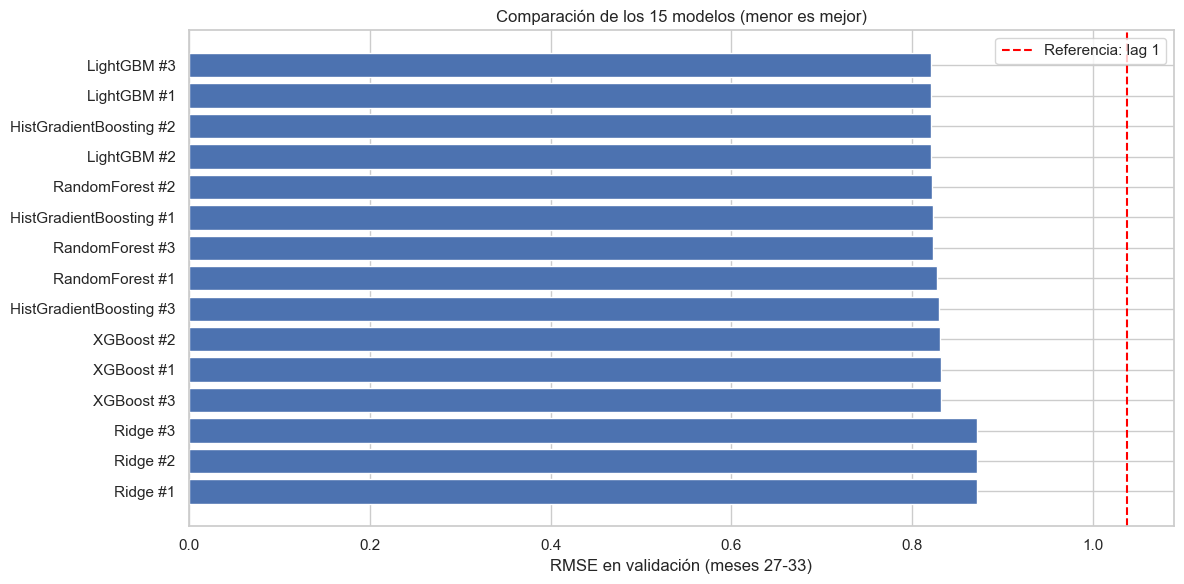

,familia,modelo,rmse_train,rmse_valid,segundos
0,LightGBM,LightGBM #3,0.695940,0.819992,14.215661
2,HistGradientBoosting,HistGradientBoosting #2,0.751556,0.820651,13.062399
4,RandomForest,RandomForest #2,0.818195,0.821401,26.174904
9,XGBoost,XGBoost #2,0.670219,0.830365,17.678334
12,Ridge,Ridge #3,0.923217,0.871663,0.192457


In [8]:
fig, ax = plt.subplots(figsize=(12, 6))
orden = tabla.sort_values("rmse_valid", ascending=False)
ax.barh(orden["modelo"], orden["rmse_valid"], color="#4C72B0")
ax.axvline(referencias["rmse_valid"].iloc[2], ls="--", color="red", label="Referencia: lag 1")
ax.set_xlabel("RMSE en validación (meses 27-33)")
ax.set_title("Comparación de los 15 modelos (menor es mejor)")
ax.legend()
plt.tight_layout()
plt.savefig(FIGS / "04_comparacion_modelos.png", dpi=120, bbox_inches="tight")
plt.show()

mejor_por_familia = tabla.loc[tabla.groupby("familia")["rmse_valid"].idxmin()].sort_values("rmse_valid")
mejor_por_familia[["familia", "modelo", "rmse_train", "rmse_valid", "segundos"]]

Modelo ganador: LightGBM #3 | RMSE validación: 0.82


mes,27,28,29,30,31,32,33
rmse,0.8826,0.786,0.7773,0.722,0.7678,0.8903,0.8855


,filas,rmse
tipo,,
Par con historia,906783.0,0.8536
Par sin historia,707581.0,0.7748


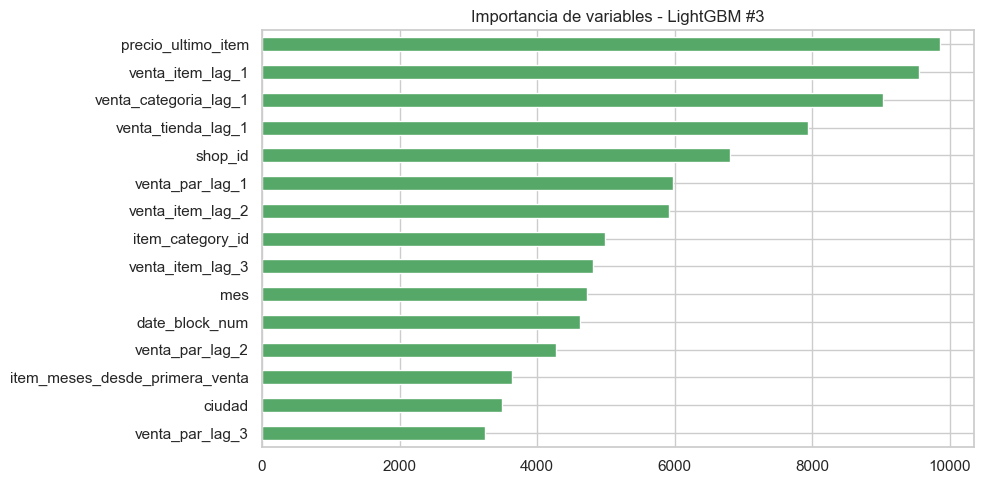

In [9]:
GANADOR = tabla.loc[0, "modelo"]
modelo_ganador = modelos[GANADOR]
print("Modelo ganador:", GANADOR, "| RMSE validación:", round(tabla.loc[0, "rmse_valid"], 4))

pred_valid = modelo_ganador.predict(Xt_valid)
por_mes = pd.DataFrame({"mes": valid["date_block_num"], "real": y_valid, "pred": pred_valid})
rmse_mes = por_mes.groupby("mes").apply(lambda g: rmse(g["real"], g["pred"])).rename("rmse")
tipo = np.where(Xt_valid["par_nuevo"] > Xt_valid["par_nuevo"].min(), "Par sin historia", "Par con historia")
rmse_tipo = pd.DataFrame({"tipo": tipo, "real": y_valid, "pred": pred_valid}).groupby("tipo").apply(lambda g: pd.Series({"filas": len(g), "rmse": rmse(g["real"], g["pred"])}))
display(rmse_mes.round(4).to_frame().T)
display(rmse_tipo.round(4))

est = modelo_ganador.estimador_
if hasattr(est, "feature_importances_"):
    imp = pd.Series(est.feature_importances_, index=Xt_valid.columns).sort_values(ascending=False).head(15)
    fig, ax = plt.subplots(figsize=(10, 5))
    imp.sort_values().plot.barh(ax=ax, color="#55A868")
    ax.set_title(f"Importancia de variables - {GANADOR}")
    plt.tight_layout()
    plt.savefig(FIGS / "04_importancia_variables.png", dpi=120, bbox_inches="tight")
    plt.show()


El modelo ganador se agrega como **último paso** del pipeline de preprocesamiento y se **reentrena con los meses 12–33** (entrenamiento + validación), para que al predecir noviembre 2015 use la información más reciente. Se usan hasta 4 millones de filas para no exceder la memoria.

In [10]:
del Xt_train, Xt_valid, X_tr, modelos
todo = grid[grid["date_block_num"].between(config["mes_ini_train"], config["mes_fin_valid"])].reset_index(drop=True)
MAX_FILAS_FINAL = 4_000_000
if len(todo) > MAX_FILAS_FINAL:
    todo = todo.sample(MAX_FILAS_FINAL, random_state=42).reset_index(drop=True)

pipeline_completo = Pipeline(steps=clone(preprocesamiento).steps + [("modelo", clone(modelo_ganador))])
inicio = time.time()
pipeline_completo.fit(todo[COLS_ID], todo["item_cnt_month"])
print(f"Pipeline completo reentrenado con {len(todo):,} filas (meses {config['mes_ini_train']}-{config['mes_fin_valid']}) en {time.time() - inicio:,.0f} s")
pipeline_completo

Pipeline completo reentrenado con 4,000,000 filas (meses 12-33) en 66 s


,steps,"[('rezagos', ...), ('imputacion_categorica', ...), ...]"
,transform_input,None
,memory,None
,verbose,False
,historia,shop...s x 5 columns]
,items,item_i...s x 3 columns]
,tiendas,shop_id ...vl Física
,rezagos_par,"[1, 2, ...]"
,rezagos_item,"[1, 2, ...]"
,rezagos_tienda,[1]
,rezagos_categoria,[1]


el pipeline completo se guardó en `models/pipeline_completo.pkl` (**22.0 MB**, comprimido), el **segundo entregable**. Al cargarlo produce exactamente las mismas predicciones que el original (diferencia 0.0). También se guardó `models/modelo_ganador.json` con el nombre, los hiperparámetros y el RMSE del modelo elegido.

In [11]:
ruta = MODELS / "pipeline_completo.pkl"
joblib.dump(pipeline_completo, ruta, compress=3)
print(f"Guardado: {ruta.name}  ({ruta.stat().st_size / 1e6:,.1f} MB)")
cargado = joblib.load(ruta)
prueba = valid[COLS_ID].head(5000)
print("Cargado vs original: diferencia máx =", float(np.abs(cargado.predict(prueba) - pipeline_completo.predict(prueba)).max()))
with open(MODELS / "modelo_ganador.json", "w", encoding="utf-8") as f:
    json.dump({"modelo": GANADOR, "parametros": tabla.loc[0, "parametros"], "rmse_valid": tabla.loc[0, "rmse_valid"]}, f, ensure_ascii=False, indent=2)

Guardado: pipeline_completo.pkl  (22.0 MB)
Cargado vs original: diferencia máx = 0.0



1. **Se entrenaron 15 modelos** (5 algoritmos × 3 configuraciones) con validación **temporal secuencial**: entrenamiento con los meses 12–26 y validación con los meses 27–33, sin mezclar el orden del tiempo.

2. **Modelo ganador: LightGBM #3** (800 árboles, tasa de aprendizaje 0.03, 127 hojas), con **RMSE de validación = 0.8200**:
   - **21 % mejor** que repetir la venta del mes anterior (1.037).
   - **27 % mejor** que predecir siempre 0 (1.116).

3. **Los modelos de árboles superan al lineal.** Ridge (0.872) no captura las interacciones entre tienda, producto, categoría y temporada. Los modelos de boosting y Random Forest sí las aprenden y quedan todos entre 0.820 y 0.831.

4. **La ingeniería de características es lo que más aporta.** Las diferencias entre los mejores algoritmos son mínimas (milésimas), mientras que la diferencia frente a las referencias es grande. Las variables más usadas por el modelo son el **precio**, los **rezagos del producto, la categoría y la tienda**, y la **tienda** como variable exógena: confirma que tratar tienda y producto como variables exógenas fue clave.

5. **Más complejidad no siempre es mejor.** Las configuraciones más complejas bajan mucho el error de entrenamiento pero no el de validación (XGBoost #3: 0.61 frente a 0.83). Por eso la selección se hace siempre con la validación.

6. **Limitaciones:**
   - El error sube en los meses con **eventos y lanzamientos** (septiembre y octubre 2015), que no se repiten de forma regular y no hay variables que los anticipen.
   - Para que el entrenamiento fuera manejable, los modelos se compararon con una muestra de 1 millón de filas y el modelo final se reentrenó con 4 millones.

7. **Resultado:** el pipeline completo (preprocesamiento + LightGBM #3), reentrenado con los meses 12–33, se guardó en `models/pipeline_completo.pkl` (**22 MB**). Es el que se usa en el notebook 05 para predecir noviembre 2015.